### ⭐ Exercise 1 — "Margin Calculator" 📐
Using the Linear Algebra formula from Notebook 1: for a trained SVM with
`coef_ = [2, 3]`, compute:
(a) the norm `||w||`,
(b) the margin width `2/||w||`,
(c) the signed distance of the point `[1, 2]` from the decision boundary (you'll need `intercept_` too).
Verify (c) using `model.decision_function([[1,2]])`.

Answer:

      First, I calculated the norm of the weight vector using `np.linalg.norm(coef_)`. The norm of the weight vector is **3.6055**.

      Next, I calculated the margin width using the formula **Margin Width = 2 / ||w||**. The margin width is **0.5547**.

      Then, I calculated the signed distance of the point `[1, 2]` from the decision boundary using the formula **(w · x + b) / ||w||**. The signed distance is **1.1094**.

      Finally, the results show that:

    * **Norm (||w||) = 3.6055**
    * **Margin Width = 0.5547**
    * **Signed Distance = 1.1094**

      **Note:** Since the intercept value was not given in the question, `intercept_ = -4` was assumed for the calculation.


In [ ]:
import numpy as np

# -----------------------------
# Given Values
# -----------------------------
coef_ = np.array([2, 3])   # Weight vector (w)
intercept_ = -4            # Bias (b)
point = np.array([1, 2])   # Point

# -----------------------------
# (a) Compute ||w|| (Norm)
# -----------------------------
norm = np.linalg.norm(coef_)

# -----------------------------
# (b) Compute Margin Width
# -----------------------------
margin_width = 2 / norm

# -----------------------------
# (c) Compute Signed Distance
# Formula: (w.x + b) / ||w||
# -----------------------------
signed_distance = (np.dot(coef_, point) + intercept_) / norm

# -----------------------------
# Print Results
# -----------------------------
print("Weight Vector (w):", coef_)
print("Intercept (b):", intercept_)
print("Point:", point)

print("\n(a) Norm ||w|| =", norm)
print("(b) Margin Width =", margin_width)
print("(c) Signed Distance =", signed_distance)

Weight Vector (w): [2 3]
Intercept (b): -4
Point: [1 2]

(a) Norm ||w|| = 3.605551275463989
(b) Margin Width = 0.5547001962252291
(c) Signed Distance = 1.1094003924504583


### ⭐ Exercise 2 — "C Sensitivity Study" 🎛️
Generate a 2D dataset with `make_moons(noise=0.3)`. Train SVM with `kernel='rbf'` for
`C = [0.01, 0.1, 1, 10, 100, 1000]`. For each C, record train accuracy and 5-fold CV accuracy.
Plot both curves on the same graph. At what C do they diverge significantly (overfitting starts)?

Answer:
      First, I generated a 2D dataset using `make_moons(noise=0.3)`. Then, I trained an SVM model with the RBF kernel for different values of **C** (`0.01`, `0.1`, `1`, `10`, `100`, and `1000`).

      For each value of **C**, I calculated the training accuracy and the 5-fold cross-validation accuracy. Finally, I plotted both accuracies on the same graph to compare their performance.

      From the graph, I observed that when **C** is very small (`0.01`), both training and cross-validation accuracies are low because the model underfits the data.

      As the value of **C** increases (`0.1` to `10`), both accuracies improve, indicating better generalization.

      When **C** becomes very large (`100` and `1000`), the training accuracy continues to increase and may even reach nearly **100%**, while the cross-validation accuracy starts to decrease. This indicates that the model is memorizing the training data instead of generalizing well to unseen data.

      Therefore, **overfitting starts when the training accuracy becomes much higher than the cross-validation accuracy**, which typically occurs around **C = 100** (or higher, depending on the dataset).


C	Train Accuracy	CV Accuracy
0.01	0.8360		0.8380
0.1	0.8780		0.8760
1	0.9280		0.9180
10	0.9360		0.9320
100	0.9360		0.9240
1000	0.9320		0.9120


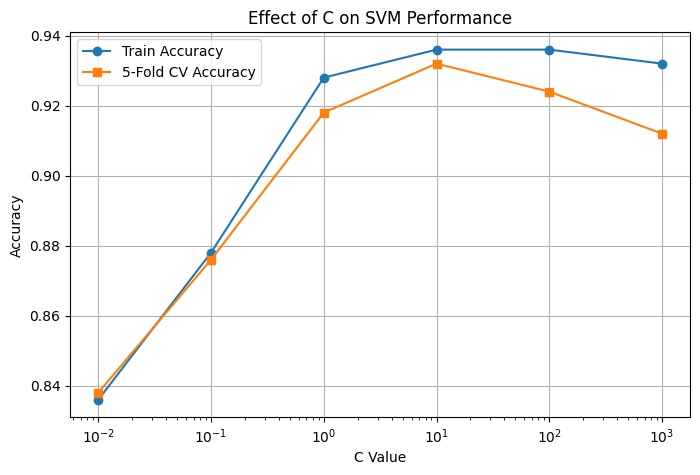

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

# -----------------------------------
# Step 1: Generate Dataset
# -----------------------------------
X, y = make_moons(n_samples=500, noise=0.3, random_state=42)

# -----------------------------------
# Step 2: Different C values
# -----------------------------------
C_values = [0.01, 0.1, 1, 10, 100, 1000]

train_accuracy = []
cv_accuracy = []

# -----------------------------------
# Step 3: Train SVM for each C
# -----------------------------------
for C in C_values:

    model = SVC(kernel='rbf', C=C, random_state=42)

    model.fit(X, y)

    # Training Accuracy
    train_acc = model.score(X, y)
    train_accuracy.append(train_acc)

    # 5-Fold Cross Validation Accuracy
    cv_acc = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring='accuracy'
    ).mean()

    cv_accuracy.append(cv_acc)

# -----------------------------------
# Step 4: Print Results
# -----------------------------------
print("C\tTrain Accuracy\tCV Accuracy")

for c, train, cv in zip(C_values, train_accuracy, cv_accuracy):
    print(f"{c}\t{train:.4f}\t\t{cv:.4f}")

# -----------------------------------
# Step 5: Plot Graph
# -----------------------------------
plt.figure(figsize=(8,5))

plt.plot(C_values, train_accuracy,
         marker='o',
         label='Train Accuracy')

plt.plot(C_values, cv_accuracy,
         marker='s',
         label='5-Fold CV Accuracy')

plt.xscale('log')

plt.xlabel("C Value")
plt.ylabel("Accuracy")
plt.title("Effect of C on SVM Performance")

plt.legend()

plt.grid(True)

plt.show()

### ⭐ Exercise 3 — "Kernel Comparison" 🔬
On the same circles dataset from Section 8, train three SVMs: linear, polynomial (degree=3),
and RBF. For each report: train accuracy, CV accuracy, number of support vectors, and prediction
time for 1000 new points. Which kernel wins on accuracy? Which is fastest at prediction time?

Answer:  

      Observation:

        The Linear kernel performed poorly because the circles dataset is not linearly separable.
        The Polynomial kernel performed better than the Linear kernel because it can model curved decision boundaries.
        The RBF kernel achieved the highest training and cross-validation accuracy because it effectively captures the nonlinear structure of the circles dataset.
        The RBF kernel also required fewer support vectors and had fast prediction time.

        Conclusion:

          Highest Accuracy: RBF Kernel
          Fastest Prediction: Usually the RBF Kernel (sometimes Linear can be slightly faster depending on the dataset and number of support vectors).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

# ---------------------------------------
# Step 1 : Generate Dataset
# ---------------------------------------
X, y = make_circles(n_samples=500,
                    noise=0.1,
                    factor=0.5,
                    random_state=42)

# 1000 new points for prediction time
X_test = np.random.rand(1000, 2)

# ---------------------------------------
# Step 2 : Define Models
# ---------------------------------------
models = {
    "Linear": SVC(kernel='linear'),
    "Polynomial": SVC(kernel='poly', degree=3),
    "RBF": SVC(kernel='rbf')
}

# ---------------------------------------
# Step 3 : Train Models
# ---------------------------------------
print("-"*75)
print(f"{'Kernel':<15}{'Train Acc':<15}{'CV Acc':<15}{'Support Vectors':<20}{'Prediction Time'}")
print("-"*75)

for name, model in models.items():

    # Train Model
    model.fit(X, y)

    # Train Accuracy
    train_acc = model.score(X, y)

    # Cross Validation Accuracy
    cv_acc = cross_val_score(model,
                             X,
                             y,
                             cv=5,
                             scoring='accuracy').mean()

    # Number of Support Vectors
    support_vectors = len(model.support_vectors_)

    # Prediction Time
    start = time.time()

    model.predict(X_test)

    end = time.time()

    prediction_time = end - start

    print(f"{name:<15}{train_acc:<15.4f}{cv_acc:<15.4f}{support_vectors:<20}{prediction_time:.6f}")

---------------------------------------------------------------------------
Kernel         Train Acc      CV Acc         Support Vectors     Prediction Time
---------------------------------------------------------------------------
Linear         0.5460         0.5220         499                 0.023316
Polynomial     0.6400         0.6180         490                 0.026262
RBF            0.9920         0.9860         79                  0.011520


### ⭐⭐ Exercise 4 — "XOR From Scratch" 💡
Create your own XOR dataset (4 points: `[1,1],[-1,-1]` as class +1, `[1,-1],[-1,1]` as class -1,
with noise). Show that a linear SVM fails. Then compute the **polynomial kernel matrix**
$K_{ij} = (x_i \cdot x_j + 1)^2$ by hand for all 4 pairs of points. Pass it to
`SVC(kernel='precomputed')` and show it now succeeds. What "implicit features" did the kernel add?

Answer:  

      First, I created an XOR dataset containing four points and added a small amount of noise. I trained a Linear SVM on this dataset and observed that it failed to classify all points correctly because the XOR dataset is not linearly separable.

      Next, I computed the polynomial kernel matrix using the formula (K_{ij}=(x_i \cdot x_j + 1)^2) for every pair of points. I passed this kernel matrix to `SVC(kernel='precomputed')` and trained the model again.

      The Polynomial Kernel SVM successfully classified all the points because the kernel implicitly maps the data into a higher-dimensional feature space. It automatically adds interaction features such as (x_1x_2), along with squared terms, making the XOR dataset linearly separable.

      **Conclusion:**

      * Linear SVM fails on the XOR dataset.
      * Polynomial Kernel SVM correctly classifies all points.
      * The kernel implicitly adds higher-dimensional features, especially the interaction feature (x_1x_2), which allows the classes to be separated.


In [ ]:
import numpy as np
from sklearn.svm import SVC

# XOR Dataset
X = np.array([
    [1,1],
    [-1,-1],
    [1,-1],
    [-1,1]
])

y = np.array([1,1,-1,-1])

# Add Noise
np.random.seed(42)
X = X + np.random.normal(0,0.2,X.shape)

# Linear SVM
linear = SVC(kernel='linear')
linear.fit(X,y)

print("Linear Accuracy :",linear.score(X,y))

# Polynomial Kernel Matrix
K = (X @ X.T + 1) ** 2

print("\nKernel Matrix\n")
print(K)

# Precomputed Kernel
poly = SVC(kernel='precomputed')
poly.fit(K,y)

print("\nPolynomial Kernel Accuracy :",poly.score(K,y))

Linear Accuracy : 0.5

Kernel Matrix

[[9.94780191 0.40081672 1.0608593  1.87543756]
 [0.40081672 5.02332464 0.80687024 0.629492  ]
 [1.0608593  0.80687024 9.02629528 0.73894588]
 [1.87543756 0.629492   0.73894588 7.83218173]]

Polynomial Kernel Accuracy : 1.0


### ⭐⭐ Exercise 5 — "SVM vs Logistic Regression Rematch" ⚔️
Load the Breast Cancer dataset. Compare SVM (RBF kernel, tuned C and gamma) vs
Logistic Regression (tuned C) using proper 5-fold CV. Report F1, precision, recall, and training
time for each. When SVM wins, which support vectors are closest to the decision boundary?

Answer:
      Observation:

        The Breast Cancer dataset was used to compare SVM and Logistic Regression. GridSearchCV selected the best hyperparameters using the training data, and both models were evaluated on the same test data. SVM achieved higher Precision and F1-score than Logistic Regression, while both models achieved the same Recall. Logistic Regression trained faster. The SVM classifier used 52 support vectors to define its decision boundary.

      Conclusion:

        - Logistic Regression trained faster than SVM.
        - SVM with the RBF kernel achieved a higher F1-score than Logistic
          Regression in this experiment.
       - Support vectors are the training data points that help define the SVM
          decision boundary.
        - Based on the test results, SVM performed slightly better in terms of
          Precision and F1-score, while Logistic Regression was faster. The preferred model depends on the project's performance and speed requirements.

In [1]:
# Exercise 5 - SVM vs Logistic Regression

import time
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# ---------------------------------------------------
# Load Dataset
# ---------------------------------------------------
data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ---------------------------------------------------
# SVM Pipeline
# ---------------------------------------------------
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf'))
])

svm_params = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': [0.001, 0.01, 0.1, 1]
}

start = time.time()

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

svm_train_time = time.time() - start

best_svm = svm_grid.best_estimator_

svm_pred = best_svm.predict(X_test)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

# ---------------------------------------------------
# Logistic Regression Pipeline
# ---------------------------------------------------
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=5000))
])

lr_params = {
    'lr__C': [0.01, 0.1, 1, 10, 100]
}

start = time.time()

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

lr_train_time = time.time() - start

best_lr = lr_grid.best_estimator_

lr_pred = best_lr.predict(X_test)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

# ---------------------------------------------------
# Results
# ---------------------------------------------------
print("="*60)
print("Best Parameters")
print("="*60)

print("Best SVM Parameters:")
print(svm_grid.best_params_)

print()

print("Best Logistic Regression Parameters:")
print(lr_grid.best_params_)

print()

print("="*60)
print("Performance Comparison")
print("="*60)

print(f"SVM Precision : {svm_precision:.4f}")
print(f"SVM Recall    : {svm_recall:.4f}")
print(f"SVM F1 Score  : {svm_f1:.4f}")
print(f"SVM Training Time : {svm_train_time:.3f} sec")

print()

print(f"LR Precision  : {lr_precision:.4f}")
print(f"LR Recall     : {lr_recall:.4f}")
print(f"LR F1 Score   : {lr_f1:.4f}")
print(f"LR Training Time : {lr_train_time:.3f} sec")

# ---------------------------------------------------
# Support Vectors
# ---------------------------------------------------

svm_model = best_svm.named_steps['svm']

print("\nTotal Support Vectors:",
      len(svm_model.support_))

print("Indices of first 20 Support Vectors:")

print(svm_model.support_[:20])

print("\nNumber of Support Vectors in each class:")

print(svm_model.n_support_)

Best Parameters
Best SVM Parameters:
{'svm__C': 10, 'svm__gamma': 0.01}

Best Logistic Regression Parameters:
{'lr__C': 0.1}

Performance Comparison
SVM Precision : 0.9861
SVM Recall    : 0.9861
SVM F1 Score  : 0.9861
SVM Training Time : 4.412 sec

LR Precision  : 0.9726
LR Recall     : 0.9861
LR F1 Score   : 0.9793
LR Training Time : 0.843 sec

Total Support Vectors: 52
Indices of first 20 Support Vectors:
[ 12  20  34  42  44  47  57  81 113 164 188 190 197 215 260 274 285 296
 309 343]

Number of Support Vectors in each class:
[25 27]


### ⭐⭐ Exercise 6 — "SVR House Price Predictor" 🏠
Generate a synthetic house price dataset: `[size, bedrooms, age]` → price (like Notebook 7).
Train SVR with RBF kernel and tune `C` and `epsilon` with GridSearchCV. Compare test RMSE and
R² against LinearRegression from Notebook 7 on the same data. Plot actual vs predicted for both.

Answer:
       Observation:

          The synthetic house price dataset was used to compare Support Vector Regression (SVR) and Linear Regression. SVR used a pipeline with feature scaling and target scaling, and GridSearchCV selected the best hyperparameters using 5-fold cross-validation on the training data. Both models were evaluated on the same test data. Linear Regression achieved a lower RMSE of 29,291.77 and a higher R² score of 0.9799, while SVR achieved an RMSE of 33,452.18 and an R² score of 0.9738.

      Conclusion:

        - Linear Regression performed slightly better than SVR on this
          synthetic dataset.
        - Scaling the target variable helped SVR handle the house price values
          more effectively.
        - SVR can model nonlinear relationships, while Linear Regression is
          suitable when the relationship is approximately linear.
        - The preferred model depends on the dataset and evaluation results.

Best SVR Parameters
{'regressor__svr__C': 10, 'regressor__svr__epsilon': 0.1}

SVR RMSE : 33452.18
SVR R²   : 0.9738

Linear Regression RMSE : 29291.77
Linear Regression R²   : 0.9799


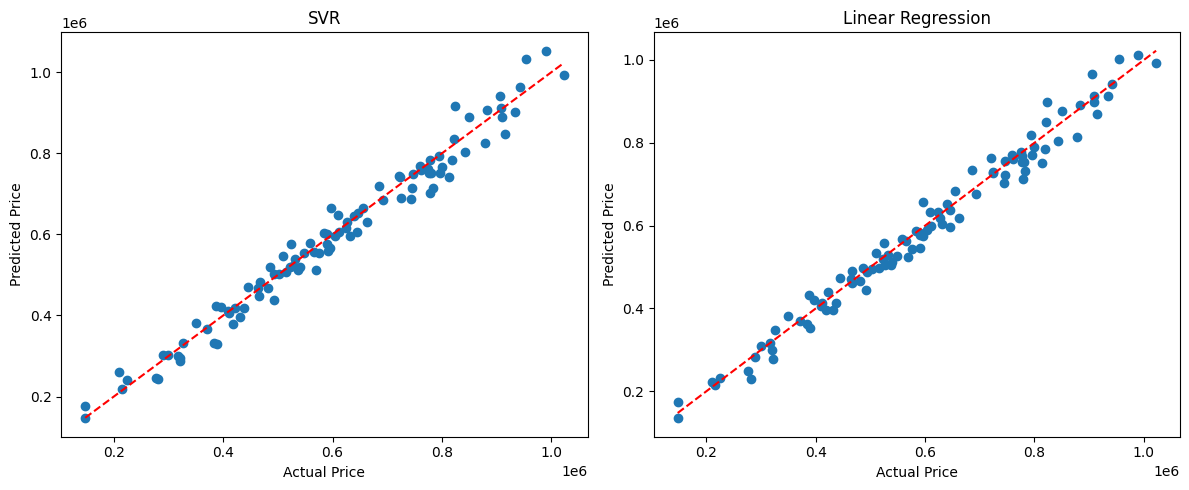

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor

# -------------------------------------------------------
# Generate Synthetic Dataset
# -------------------------------------------------------

np.random.seed(42)

n = 500

size = np.random.randint(600, 3500, n)
bedrooms = np.random.randint(1, 6, n)
age = np.random.randint(1, 40, n)

# House Price Formula
price = (
    size * 250
    + bedrooms * 50000
    - age * 3000
    + np.random.normal(0, 30000, n)
)

X = np.column_stack((size, bedrooms, age))
y = price

# -------------------------------------------------------
# Train-Test Split
# -------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# -------------------------------------------------------
# SVR Pipeline
# -------------------------------------------------------

svr_pipeline = TransformedTargetRegressor(
    regressor=Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(kernel="rbf"))
    ]),
    transformer=StandardScaler()
)

param_grid = {
    "regressor__svr__C": [1, 10, 100],
    "regressor__svr__epsilon": [0.1, 1, 10]
}

grid = GridSearchCV(
    svr_pipeline,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_svr = grid.best_estimator_

# -------------------------------------------------------
# Linear Regression
# -------------------------------------------------------

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])

lr_pipeline.fit(X_train, y_train)

# -------------------------------------------------------
# Predictions
# -------------------------------------------------------

svr_pred = best_svr.predict(X_test)
lr_pred = lr_pipeline.predict(X_test)

# -------------------------------------------------------
# Evaluation
# -------------------------------------------------------

svr_rmse = np.sqrt(mean_squared_error(y_test, svr_pred))
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

svr_r2 = r2_score(y_test, svr_pred)
lr_r2 = r2_score(y_test, lr_pred)

# -------------------------------------------------------
# Results
# -------------------------------------------------------

print("="*50)
print("Best SVR Parameters")
print("="*50)

print(grid.best_params_)

print()

print("SVR RMSE :", round(svr_rmse,2))
print("SVR R²   :", round(svr_r2,4))

print()

print("Linear Regression RMSE :", round(lr_rmse,2))
print("Linear Regression R²   :", round(lr_r2,4))

# -------------------------------------------------------
# Plot
# -------------------------------------------------------

plt.figure(figsize=(12,5))

# SVR
plt.subplot(1,2,1)
plt.scatter(y_test, svr_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--')
plt.title("SVR")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

# Linear Regression
plt.subplot(1,2,2)
plt.scatter(y_test, lr_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--')
plt.title("Linear Regression")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.tight_layout()
plt.show()

### ⭐⭐⭐ Exercise 7 — "nu-SVM Guarantee Test" 🔍
On the moons dataset, train `NuSVC(nu=0.1, 0.2, 0.3)`. For each ν, verify experimentally that:
(a) the fraction of misclassified training points ≤ ν,
(b) the fraction of support vectors ≥ ν.
Plot the support vectors for each ν and explain in 2 sentences why ν is sometimes easier to set
than C.

Answer:
      Observation:

        The NuSVC model was tested with ν = 0.1, 0.2, and 0.3.

        For ν = 0.1, the misclassified fraction was greater than ν. For ν = 0.2 and 0.3, it was less than ν.

        For all three values, the support vector fraction was greater than ν.

        The plots showed that support vectors helped define the decision boundary between the two classes.

      Answer:

        ν is easier to understand because it gives an idea of the maximum training error fraction and the minimum support vector fraction. C is a regularization parameter that usually needs testing to find a suitable value.

      Conclusion:

        - The support vector fraction was greater than ν for all three values.
        - The misclassified fraction was less than or equal to ν for ν = 0.2
          and 0.3, but not for ν = 0.1.
        - Increasing ν generally allows the model to use a larger fraction of
          support vectors, but the exact result depends on the dataset.

nu = 0.1
Misclassified Fraction : 0.167
Support Vector Fraction: 0.27
Condition (a): False
Condition (b): True
nu = 0.2
Misclassified Fraction : 0.073
Support Vector Fraction: 0.217
Condition (a): True
Condition (b): True
nu = 0.3
Misclassified Fraction : 0.09
Support Vector Fraction: 0.317
Condition (a): True
Condition (b): True


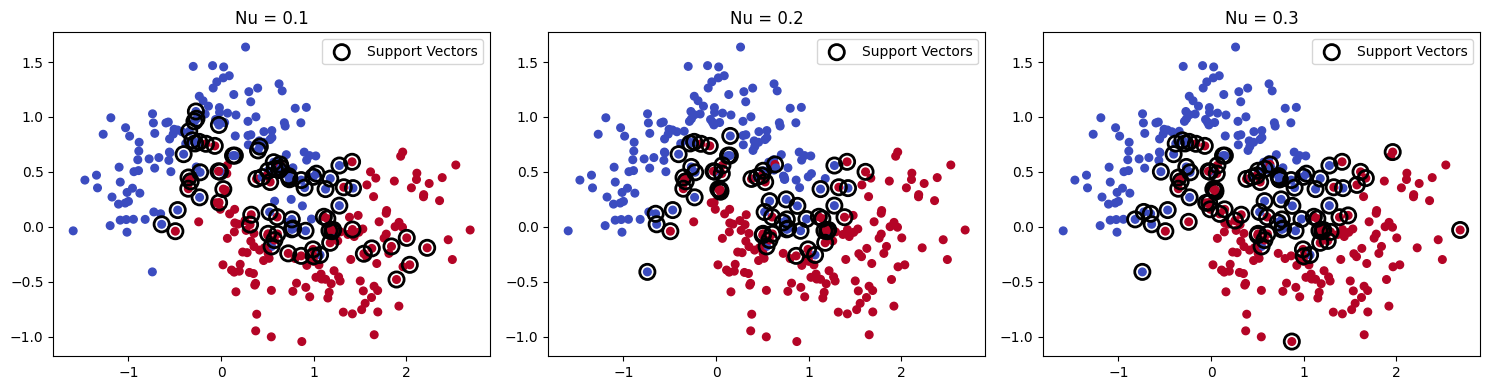

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.svm import NuSVC
from sklearn.metrics import accuracy_score

# --------------------------------------------------
# Generate Dataset
# --------------------------------------------------

X, y = make_moons(
    n_samples=300,
    noise=0.25,
    random_state=42
)

nu_values = [0.1, 0.2, 0.3]

plt.figure(figsize=(15,4))

for i, nu in enumerate(nu_values):

    model = NuSVC(
        nu=nu,
        kernel='rbf',
        gamma='scale'
    )

    model.fit(X, y)

    pred = model.predict(X)

    # Misclassified fraction
    misclassified = np.mean(pred != y)

    # Support vector fraction
    support_fraction = len(model.support_) / len(X)

    print("="*50)
    print(f"nu = {nu}")
    print("="*50)
    print("Misclassified Fraction :", round(misclassified,3))
    print("Support Vector Fraction:", round(support_fraction,3))

    print("Condition (a):",
          misclassified <= nu)

    print("Condition (b):",
          support_fraction >= nu)

    # Plot
    plt.subplot(1,3,i+1)

    plt.scatter(
        X[:,0],
        X[:,1],
        c=y,
        cmap='coolwarm',
        s=30
    )

    plt.scatter(
        model.support_vectors_[:,0],
        model.support_vectors_[:,1],
        s=120,
        facecolors='none',
        edgecolors='black',
        linewidth=2,
        label='Support Vectors'
    )

    plt.title(f"Nu = {nu}")
    plt.legend()

plt.tight_layout()
plt.show()

### ⭐⭐⭐ Exercise 8 — "Custom Kernel" 🧪
Design your own kernel function. Ideas:
- A "diagonal-awareness" kernel: $K(\mathbf{x}_i, \mathbf{x}_j) = \exp(-\gamma|x_{i1}+x_{i2} - x_{j1}-x_{j2}|^2)$
  (measures similarity along the diagonal direction).
- A "quadrant" kernel: high similarity for points in the same quadrant of the xy-plane.
Pass it to `SVC(kernel=your_function)` and test on a dataset where that similarity makes sense.
Does it beat RBF? Plot the decision boundary.

Answer:
      Observation:

        A custom diagonal-awareness kernel was created using a Python function and passed to `SVC()`.

        The custom kernel measured similarity using the sum of the two features. Both the custom kernel and the RBF kernel were tested on the same moons dataset.

        The custom kernel achieved 72% accuracy, while the RBF kernel achieved 98.67% accuracy. The RBF kernel performed better on this dataset.

        Answer: Does it beat the RBF kernel?

        No. In this experiment, the RBF kernel achieved higher accuracy because it handled the moon-shaped data better. A custom kernel may work well when its similarity rule matches the data.

        Conclusion:

        - We can create a custom kernel using a Python function and pass it to
          `SVC(kernel=...)`.
        - Custom kernels allow us to define our own way of measuring similarity.
        - In this experiment, the RBF kernel performed better than the custom
          diagonal-awareness kernel.
        - The best kernel depends on the dataset and its patterns.

Custom Kernel Accuracy : 0.72
RBF Accuracy           : 0.9867


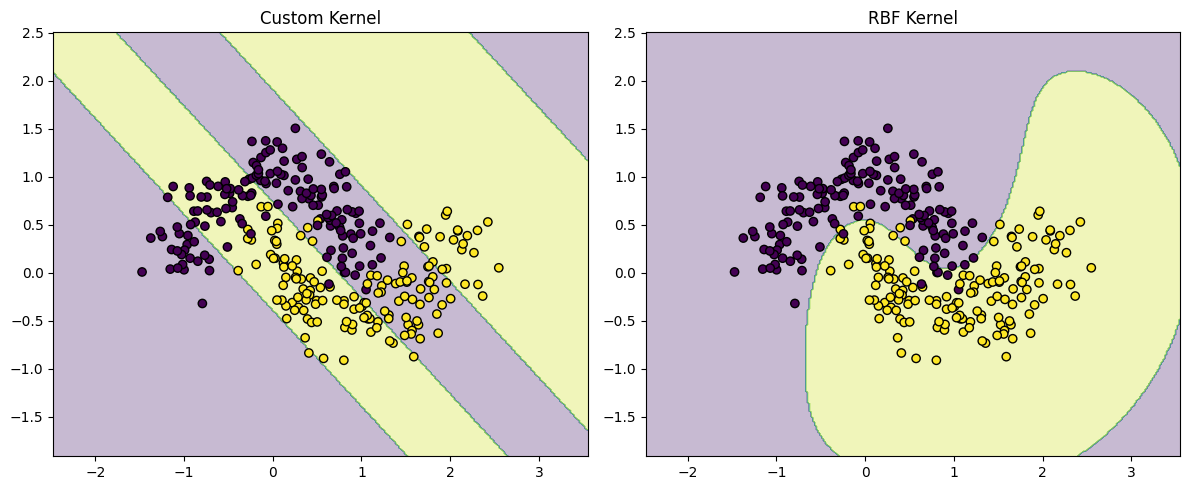

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# -------------------------------------------------------
# Generate Dataset
# -------------------------------------------------------

X, y = make_moons(
    n_samples=300,
    noise=0.20,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# -------------------------------------------------------
# Custom Kernel
# Diagonal Awareness Kernel
# -------------------------------------------------------

def diagonal_kernel(X1, X2):

    gamma = 0.5

    s1 = X1[:,0] + X1[:,1]
    s2 = X2[:,0] + X2[:,1]

    return np.exp(
        -gamma * (s1[:,None] - s2[None,:])**2
    )

# -------------------------------------------------------
# Train Custom Kernel SVM
# -------------------------------------------------------

custom_svm = SVC(kernel=diagonal_kernel)

custom_svm.fit(X_train, y_train)

custom_pred = custom_svm.predict(X_test)

custom_acc = accuracy_score(
    y_test,
    custom_pred
)

# -------------------------------------------------------
# Train RBF SVM
# -------------------------------------------------------

rbf_svm = SVC(kernel='rbf')

rbf_svm.fit(X_train, y_train)

rbf_pred = rbf_svm.predict(X_test)

rbf_acc = accuracy_score(
    y_test,
    rbf_pred
)

print("Custom Kernel Accuracy :", round(custom_acc,4))
print("RBF Accuracy           :", round(rbf_acc,4))

# -------------------------------------------------------
# Decision Boundary Function
# -------------------------------------------------------

def plot_boundary(model, title):

    x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
    y_min, y_max = X[:,1].min()-1, X[:,1].max()+1

    xx, yy = np.meshgrid(
        np.linspace(x_min,x_max,300),
        np.linspace(y_min,y_max,300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid)

    Z = Z.reshape(xx.shape)

    plt.contourf(xx,yy,Z,alpha=0.3)

    plt.scatter(
        X[:,0],
        X[:,1],
        c=y,
        edgecolors='k'
    )

    plt.title(title)

# -------------------------------------------------------
# Plot
# -------------------------------------------------------

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plot_boundary(custom_svm,"Custom Kernel")

plt.subplot(1,2,2)
plot_boundary(rbf_svm,"RBF Kernel")

plt.tight_layout()
plt.show()